In [2]:
from reading_sql.config import SNAPSHOTS_PATH
import numpy
import pandas

dataframe = pandas.read_parquet(SNAPSHOTS_PATH / "churn-query.parquet")

dataframe["media_dias_entre_pedidos"] = dataframe["tempo_relacionamento_dias"] / dataframe["total_pedidos"]
dataframe["razao_recencia_dias_entre_pedidos"] = dataframe["recencia_dias"] / dataframe["media_dias_entre_pedidos"]
dataframe.replace([numpy.inf, -numpy.inf], numpy.nan, inplace=True)

print(dataframe.columns)

Index(['user_id', 'idade', 'genero', 'pais', 'canal_aquisicao',
       'total_pedidos', 'receita_total', 'ticket_medio', 'itens_devolvidos',
       'tempo_relacionamento_dias', 'recencia_dias', 'churn',
       'media_dias_entre_pedidos', 'razao_recencia_dias_entre_pedidos'],
      dtype='str')


<Axes: xlabel='tempo_relacionamento_dias', ylabel='Count'>

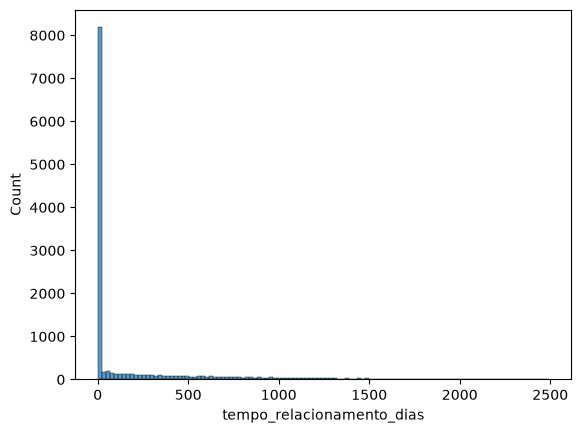

In [ ]:
import seaborn

seaborn.histplot(data=dataframe[["tempo_relacionamento_dias"]], x="tempo_relacionamento_dias")

<Axes: >

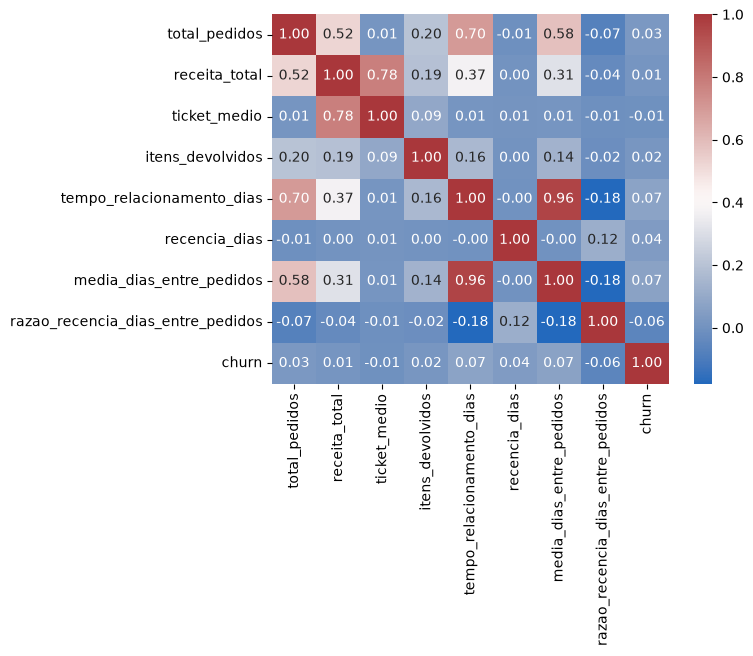

In [21]:
dataframe_heatmap = dataframe[["total_pedidos", "receita_total", "ticket_medio", "itens_devolvidos", "tempo_relacionamento_dias", "recencia_dias","media_dias_entre_pedidos", "razao_recencia_dias_entre_pedidos", "churn"]]

seaborn.heatmap(data=dataframe_heatmap.corr(), cmap="vlag", annot=True, fmt=".2f")

<Axes: xlabel='churn', ylabel='tempo_relacionamento_dias'>

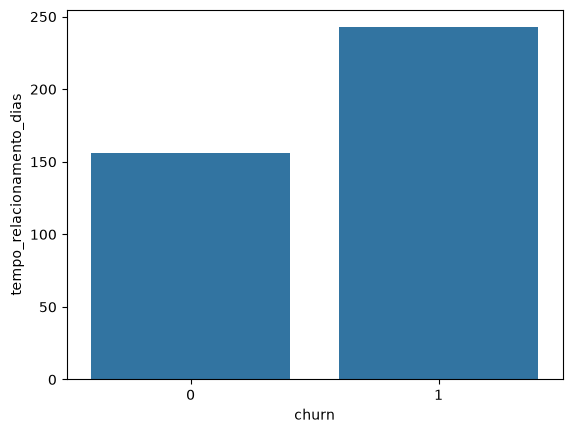

In [ ]:
seaborn.barplot(data=dataframe[["churn", "tempo_relacionamento_dias"]].groupby(by="churn").mean(), x="churn", y="tempo_relacionamento_dias")

<Axes: xlabel='churn', ylabel='razao_recencia_dias_entre_pedidos'>

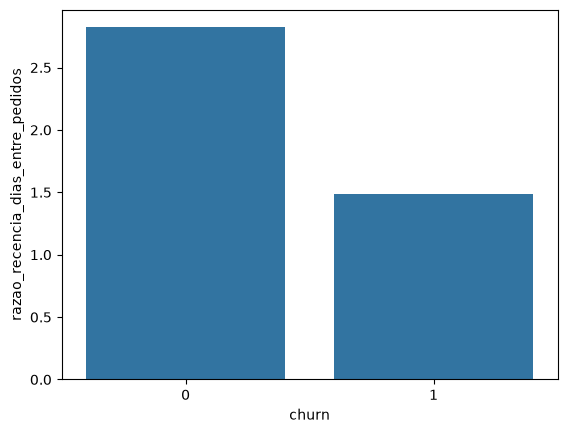

In [26]:
seaborn.barplot(data=dataframe[["churn", "razao_recencia_dias_entre_pedidos"]].groupby(by="churn").mean(), x="churn", y="razao_recencia_dias_entre_pedidos")

<Axes: xlabel='canal_aquisicao', ylabel='churn'>

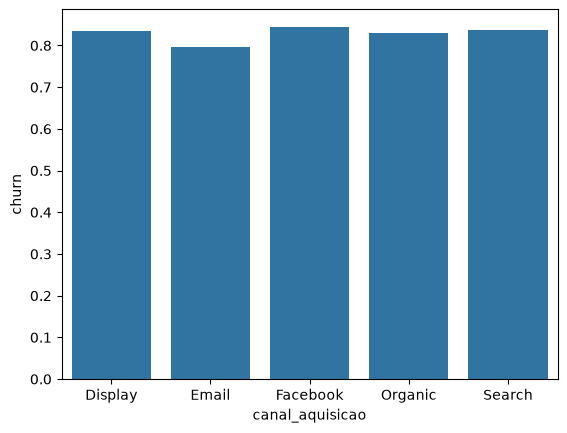

In [27]:
seaborn.barplot(data=dataframe[["churn", "canal_aquisicao"]].groupby(by="canal_aquisicao").mean(), x="canal_aquisicao", y="churn")